# PMMA directional dark field: active measured-data reconstruction
The existing measured reference grid, sample grid, and flat encode spatial transmission and directional scattering contrast. This notebook actively repeats every local correlation fit with cleaned code. The source oracle is a separately identified standard-method reconstruction, not true material microstructure.

The local Gaussian transfer is G(q)=T exp(-q^T C q/2), where q is angular spatial frequency in detector pixels, T is transmission, and C has components Cxx, Cyy, Cxy in detector-pixel squared units. Component x points right, component y up; stored image rows point down. Four grid directions constrain three symmetric moments. The unconstrained noisy estimate can have negative eigenvalues; all are retained.

In [1]:
from pathlib import Path
import os,time,json,sys
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').exists(): root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.physics_model import covariance_eigenvalues,mode_ratios
from src.visualization import conditional_eigenvalue_uncertainty,figures,export_figures
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
grid,sample=load_data(root/'data/raw_data.npz')
print('Existing measured ROI:',grid.shape,grid.dtype)

Existing measured ROI: (468, 468) float32


## Full reconstruction
At each 14 by 14 window, correlate with a 7 by 7 reference patch and fit four cosine directions with two shared phases. Average fitted amplitudes in 13 by 13 blocks before dividing sample and reference. The DC ratio gives T. The four logarithmic directional ratios are solved by the original unconstrained least-squares formula. Conditional covariance recording does not alter any fit. Expect approximately 16 minutes on one CPU thread.

In [2]:
start=time.perf_counter()
c,t,diagnostics=reconstruct(grid,sample,capture_covariance=True)
runtime=time.perf_counter()-start
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=c[None],transmission=t[None])
report=judge.evaluate(root/'output/reconstruction.npz')
print(json.dumps({'fresh_runtime_seconds':runtime,'judge':report},indent=2))
assert report['passed']

{
  "fresh_runtime_seconds": 921.2972015000014,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "cxx_ncc": 1.0,
      "cxx_nrmse": 7.519948873175182e-17,
      "cyy_ncc": 0.9999999999999999,
      "cyy_nrmse": 5.927228873688505e-17,
      "cxy_ncc": 1.0,
      "cxy_nrmse": 5.623543252154953e-17,
      "transmission_ncc": 1.0,
      "transmission_nrmse": 0.0,
      "mode_residual": 0.06614234195266892
    },
    "thresholds": {
      "cxx_ncc": {
        "comparison": ">=",
        "boundary": 0.999999
      },
      "cxx_nrmse": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "cyy_ncc": {
        "comparison": ">=",
        "boundary": 0.999999
      },
      "cyy_nrmse": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "cxy_ncc": {
        "comparison": ">=",
        "boundary": 0.999999
      },
      "cxy_nrmse": {
        "comparison": "<=",
        "boundary": 1e-05
      },
      "transmission_ncc": {
    

## Source comparison and independent physical interpretation
The original source was run twice on these exact observations before extraction. The comparison below does not align or rescale fields. The physical Gaussian model is checked separately with a known periodic Fourier blur in the unit tests. This measured sample is not perfectly stationary or Gaussian: the four directional ratios need not close exactly under a three-component model.

The transmission-only comparison sets all moments to zero. The isotropic comparison retains the fresh tensor trace, equates its diagonal components, and removes Cxy. Both are actual constrained predictions from the fresh result, not substituted reconstructions or independently fitted algorithms.

{
  "negative_locations": 141,
  "total_locations": 1225,
  "negative_fraction": 0.11510204081632654,
  "negative_abs_over_conditional_sd_quantiles": [
    0.005799907112374052,
    0.35356252962621904,
    1.2043793586190124,
    2.7600336731539805
  ],
  "negative_within_1_sd": 130,
  "negative_within_1p96_sd": 139,
  "fresh_runtime_seconds": 921.2972015000014
}


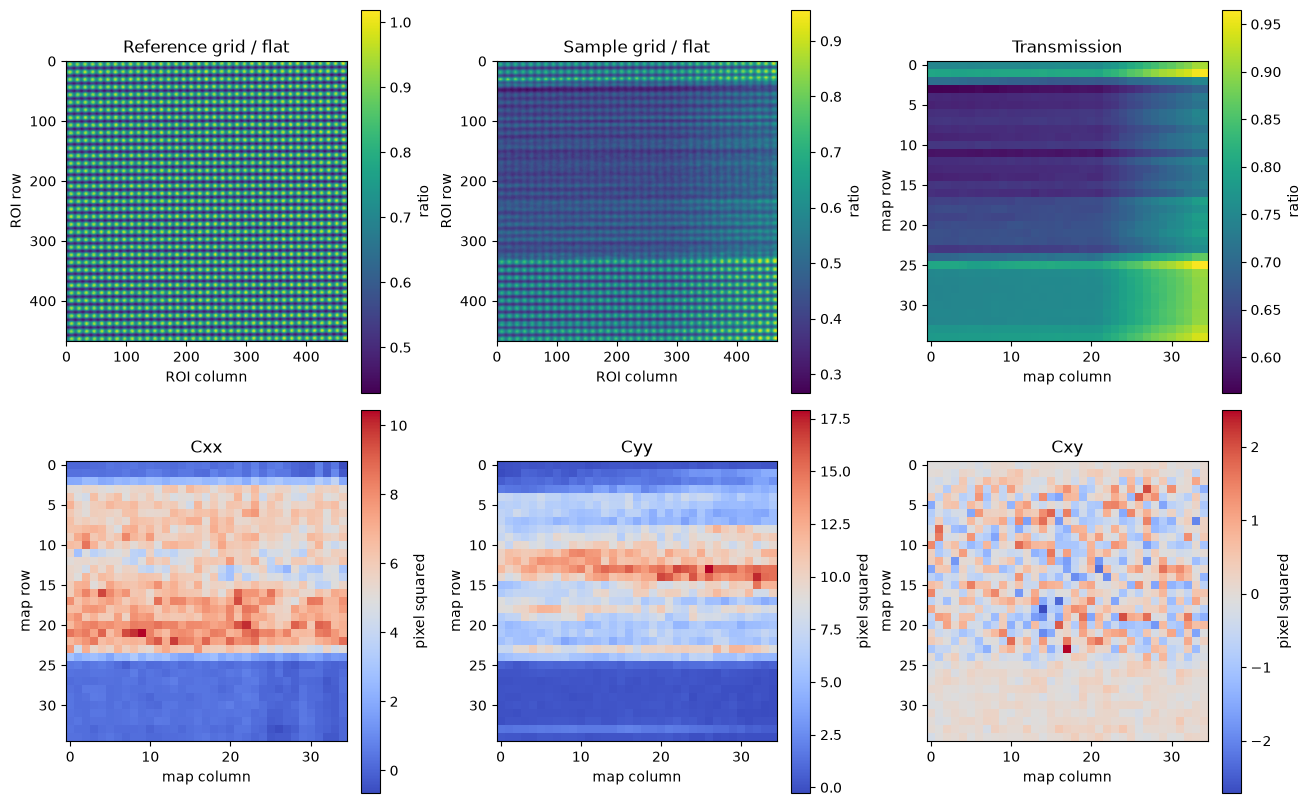

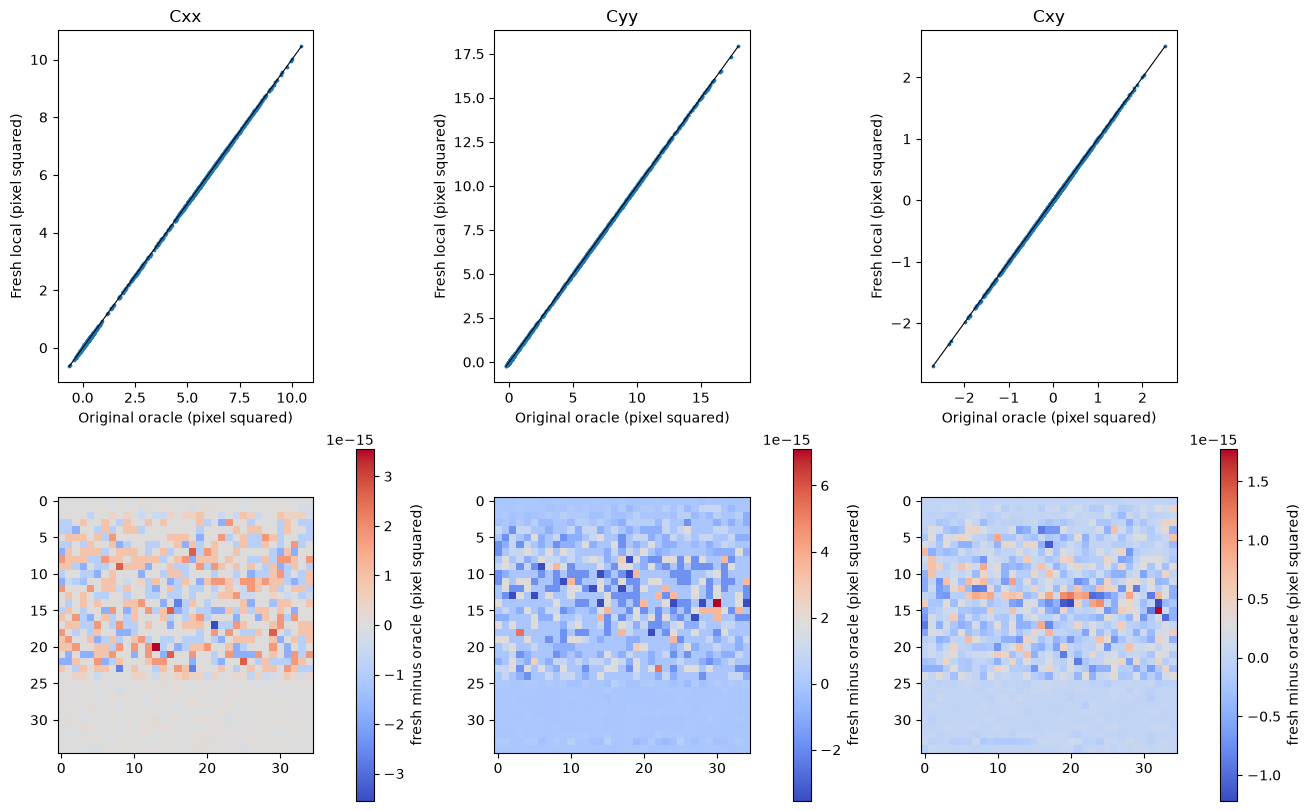

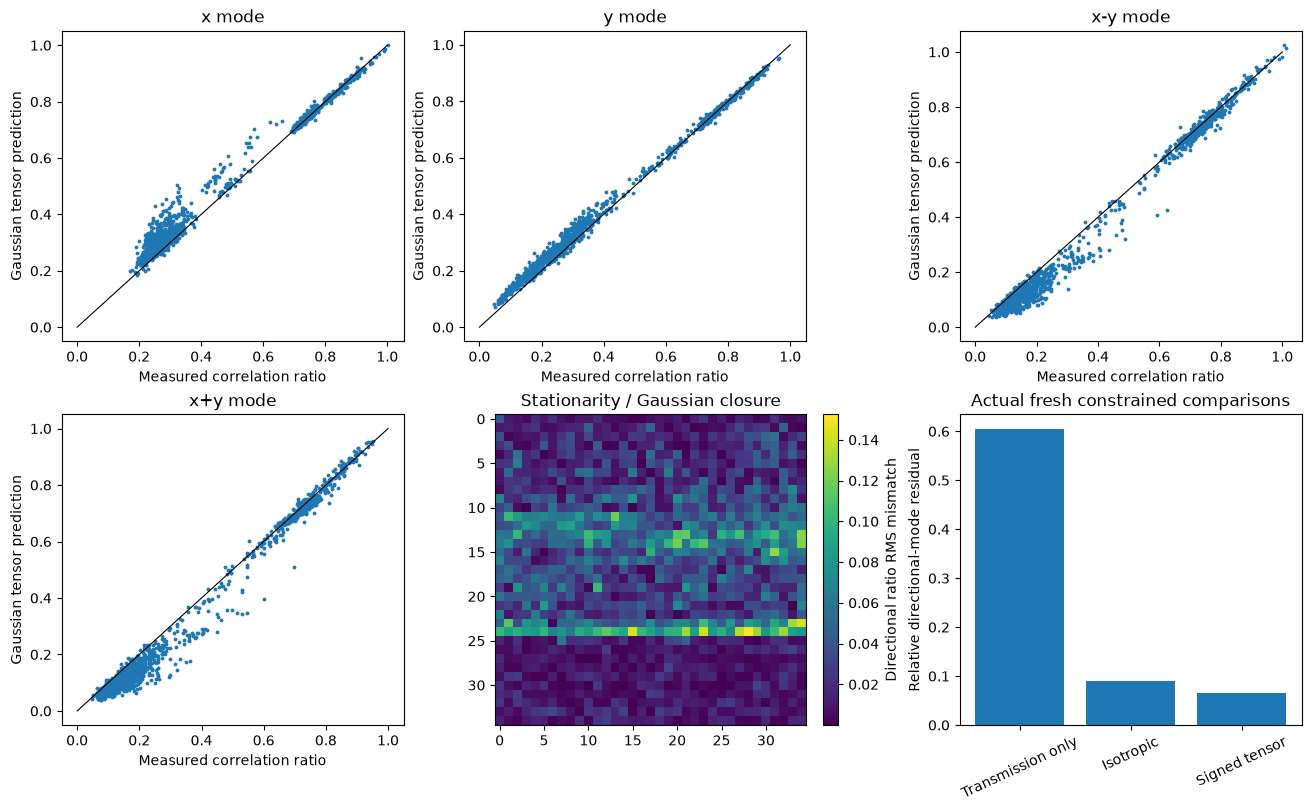

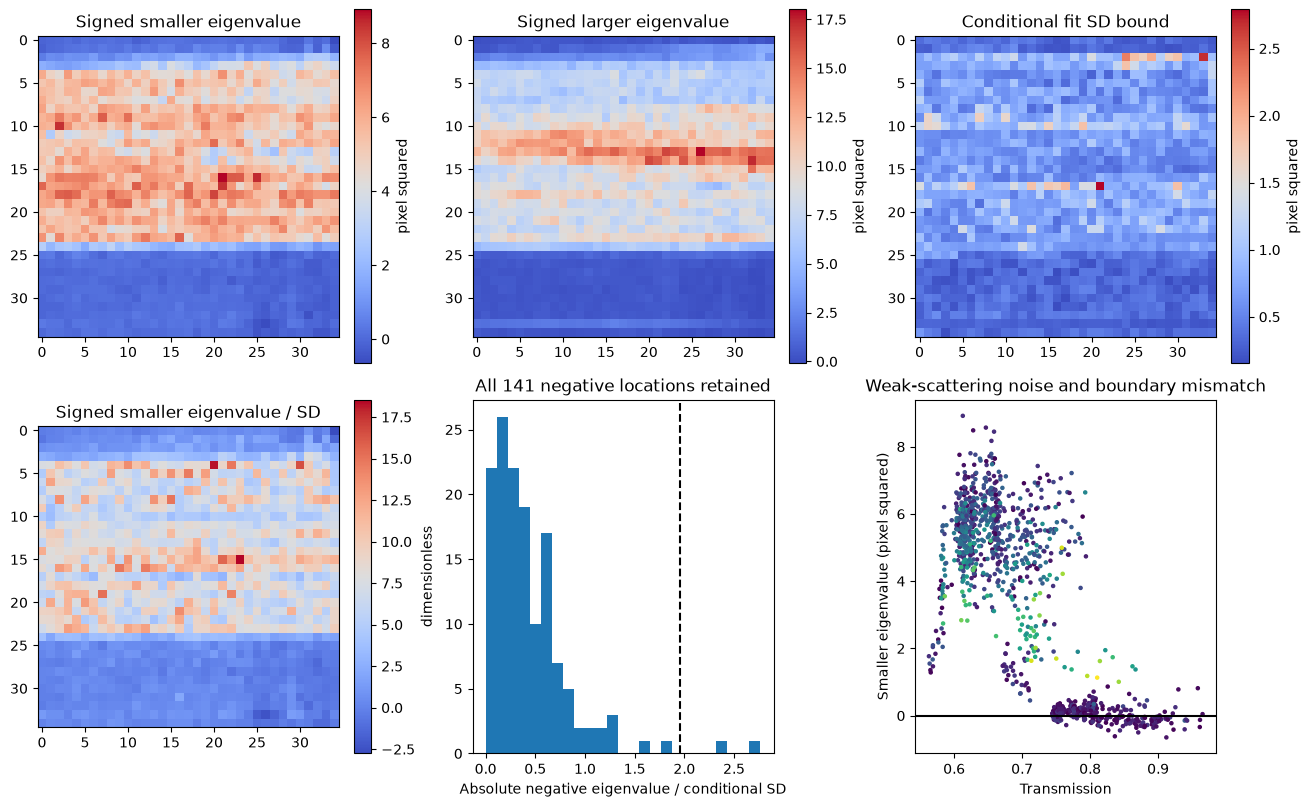

Private exported figures: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch4_20261021\material_physics\figures\pmma_grid_dark_field_tensor


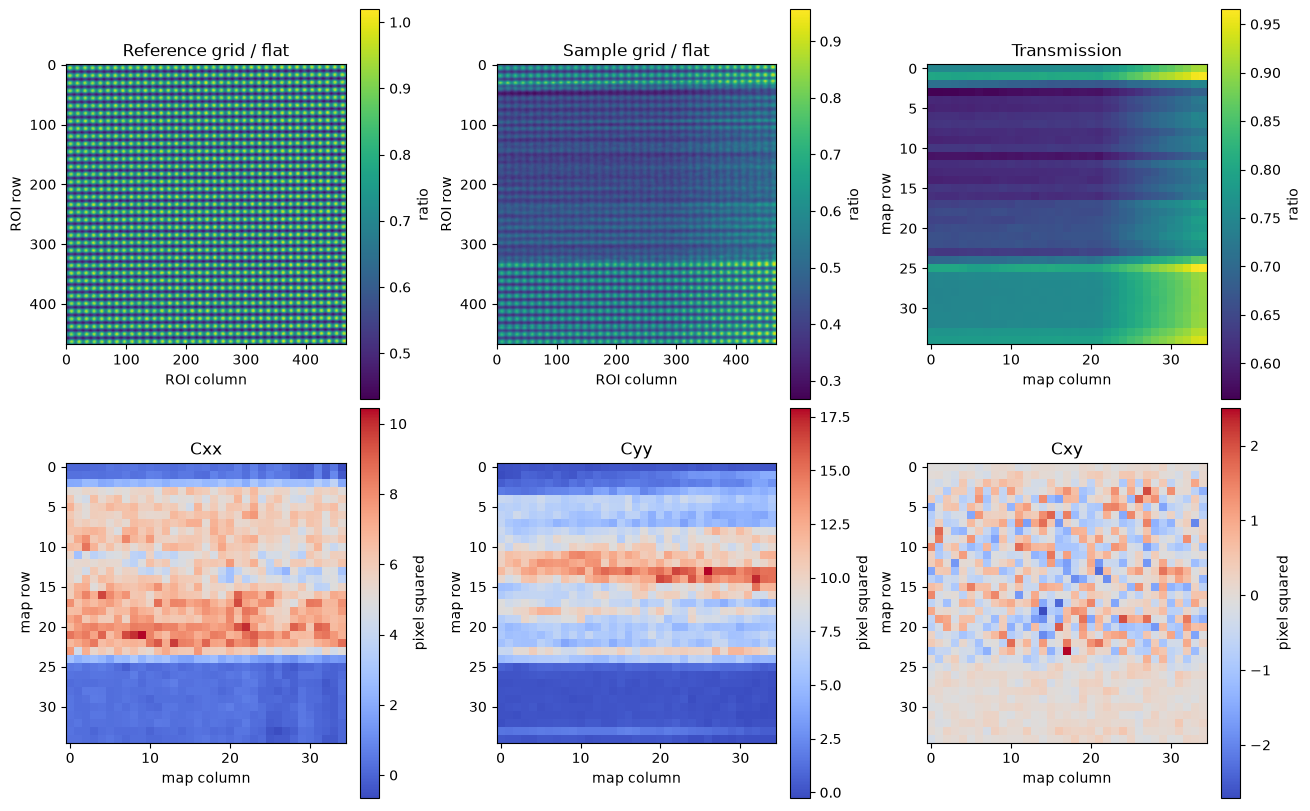

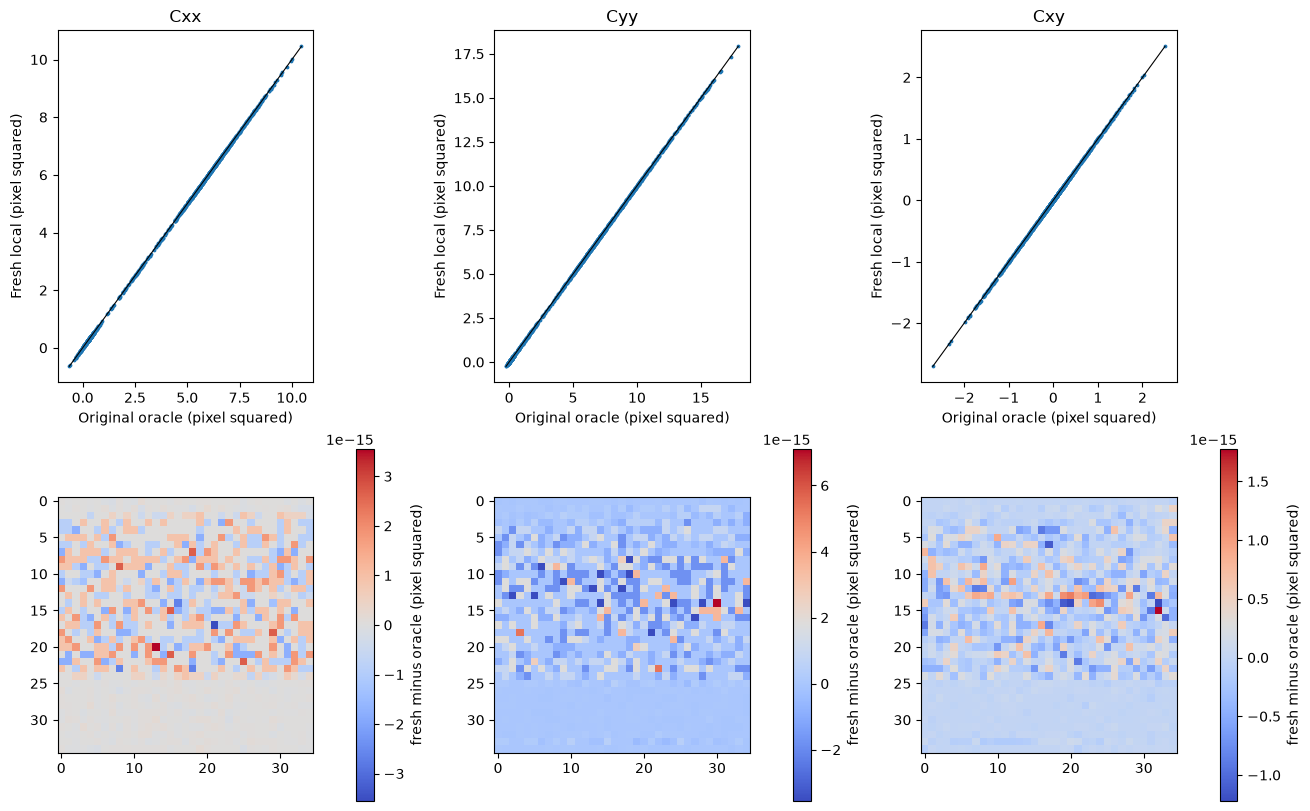

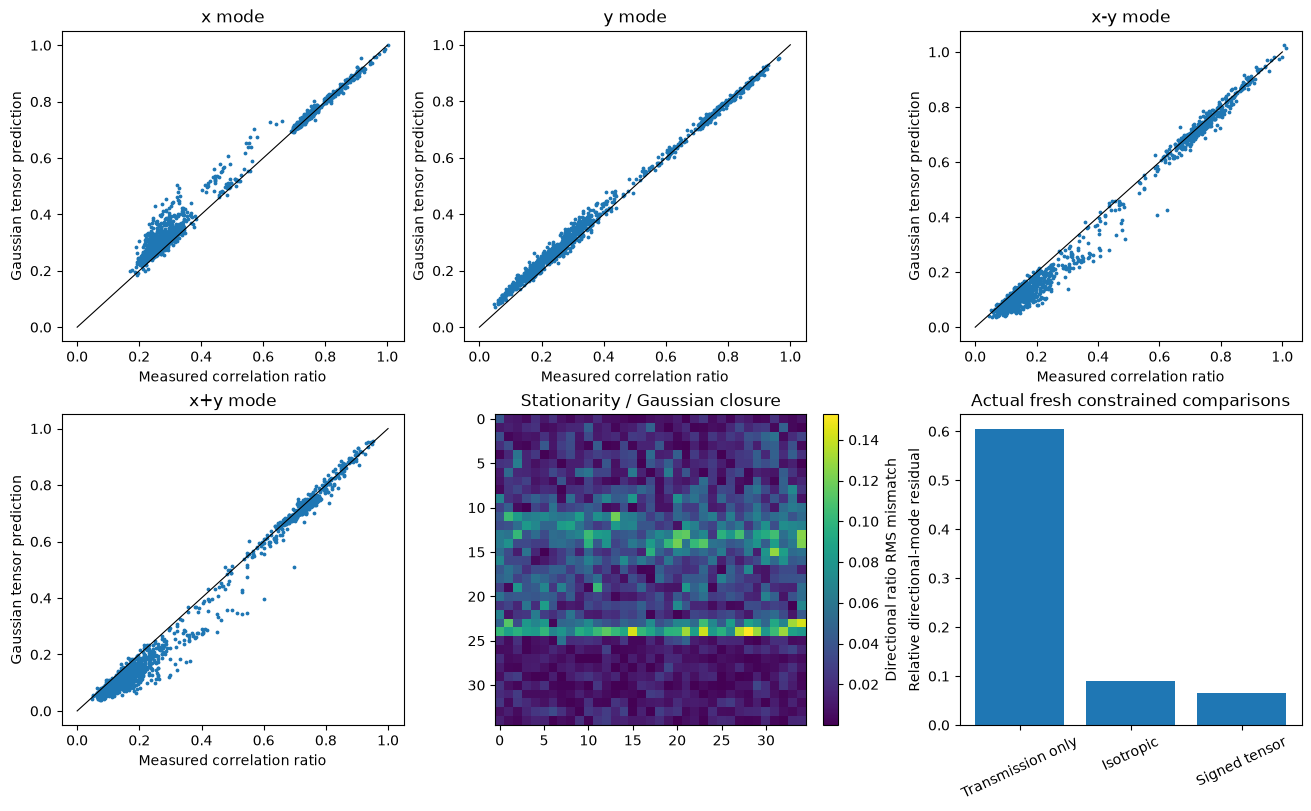

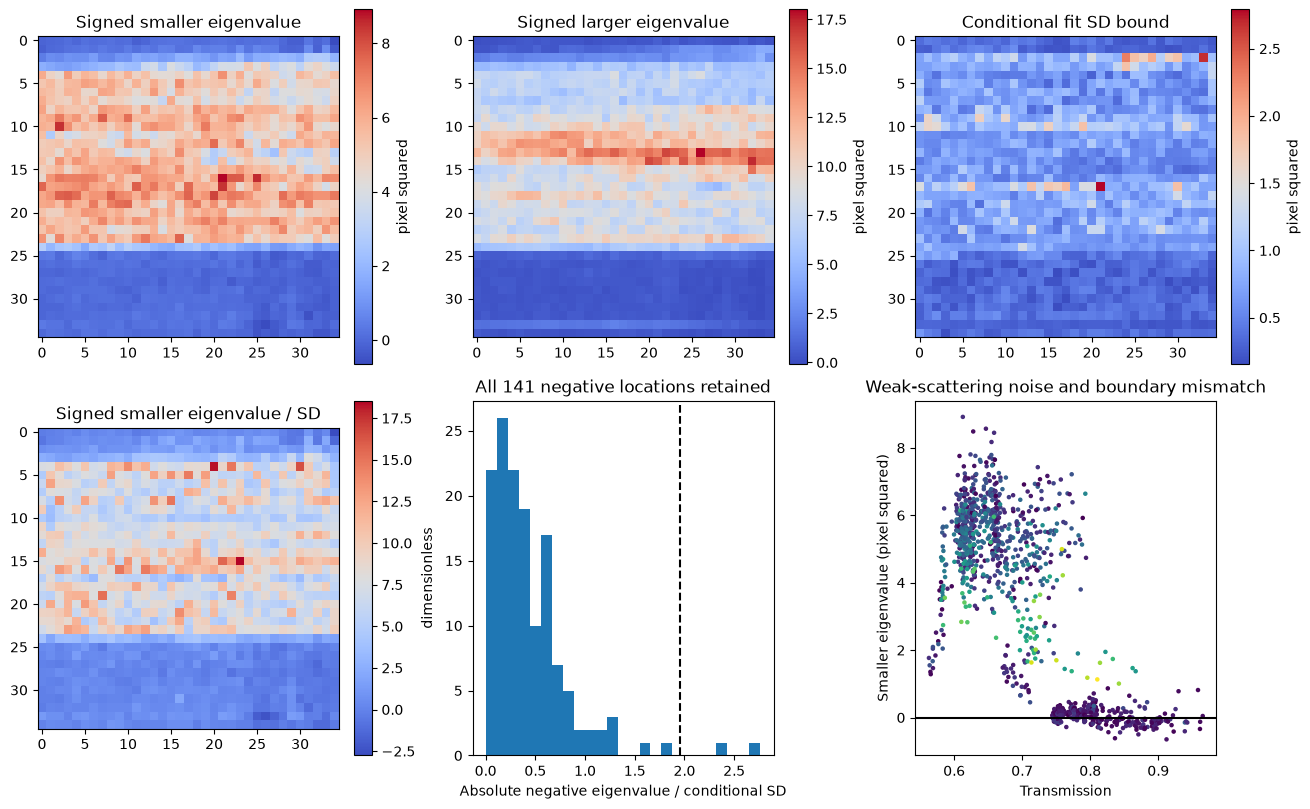

In [3]:
with np.load(root/'notebooks/reference_outputs/upstream_reconstruction.npz',allow_pickle=False) as source:
    original=source['reconstruction'][0]
sigma=conditional_eigenvalue_uncertainty(diagnostics['coefficients'],diagnostics['fit_covariance'],c)
eigen=covariance_eigenvalues(c);negative=eigen[0]<0
summary={'negative_locations':int(negative.sum()),'total_locations':int(negative.size),'negative_fraction':float(negative.mean()),'negative_abs_over_conditional_sd_quantiles':np.quantile(abs(eigen[0][negative])/sigma[negative],[0,.5,.95,1]).tolist(),'negative_within_1_sd':int(np.sum(abs(eigen[0][negative])<=sigma[negative])),'negative_within_1p96_sd':int(np.sum(abs(eigen[0][negative])<=1.96*sigma[negative])),'fresh_runtime_seconds':runtime}
print(json.dumps(summary,indent=2))
groups,numeric=figures(grid,sample,c,t,diagnostics,original,sigma)
for fig in groups.values(): display(fig)
figure_dir=Path(os.environ.get('IMAGING101_FIGURE_DIR',str(root.parent.parent.parent/'imaging-101-maintainer/research_batch4_20261021/material_physics/figures/pmma_grid_dark_field_tensor')))
export_figures(groups,numeric,figure_dir)
(figure_dir/'measurements.json').write_text(json.dumps({'summary':summary,'judge':report},indent=2),encoding='utf8')
np.savez_compressed(root/'notebooks/reference_outputs/cleaned_measurements.npz',reconstruction=c[None],transmission=t[None],conditional_sigma=sigma,mode_ratios=diagnostics['ratios'])
print('Private exported figures:',figure_dir)

## Interpretation and limits
The original method retrieves signed noisy second moments, including weak-scattering negative values near the exterior. The conditional standard-deviation diagnostic propagates curve-fit covariance through amplitude normalization, logarithms, the linear inverse, and the smallest eigenvalue. It uses a Cauchy upper bound rather than assuming independent overlapping windows; grid and sample bounds are added. These are conditional fit diagnostics, not calibrated confidence intervals for a camera noise process. The directional closure map exposes additional stationarity and model mismatch, including sample boundaries. No negative region is hidden and no positive-semidefinite projection is applied.

The strong scattering interior has positive moments; weak-scattering estimates are near zero relative to their conditional fit uncertainty. The absolute detector scale and scattering propagation geometry are not supplied, so the results remain detector-pixel squared moments. Neither chemical concentrations nor true angular covariance are claimed. All figures and comparisons above derive from the active full reconstruction.